</br>
<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>Práctica 2:
        </h2>
        <h1 style="margin-top: -10px;">
            Aprendizaje y selección de modelos de clasificación
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Minería de Datos, 2026-27
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        José Antonio Gámez Martín
                    </span>
                    <a href="mailto:Jose.Gamez@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Jose.Gamez@uclm.es
                    </a>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        Pablo Torrijos Arenas
                    </span>
                    <a href="mailto:Pablo.Torrijos@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Pablo.Torrijos@uclm.es
                    </a>
                </div>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Estudiantes
        </h3>
    </div>
    <ul style="list-style-type: none; padding-left: 28px; margin: 0;  font-size: 1.1em">
        <li>Guillermo Morcillo Conchán</li>
        <li>David Gómez Aniorte</li>
    </ul>

</div>

## 1. Introducción

El objetivo de esta práctica es construir sobre el trabajo realizado en la Práctica 1. Se aplicarán y compararán diversos modelos de clasificación supervisada, utilizando validación cruzada y ajuste de hiperparámetros, para seleccionar el modelo más eficaz en la predicción del abandono estudiantil.

Para ello, continuaréis utilizando los mismos conjuntos de datos de la práctica anterior (`uclm_student_train.csv` y `uclm_student_test.csv`). El `Pipeline` de preprocesamiento desarrollado en la Práctica 1 servirá como base para el entrenamiento de los modelos (aunque podéis modificarlo, y lo normal es que lo hagáis a medida que entendáis mejor los datos).

Tendréis que explorar y evaluar los modelos de clasificación introducidos en el notebook complementario (`Material Práctica 2 - Selección de modelos.ipynb`), junto con al menos un algoritmo adicional investigado de forma independiente, el cual tendréis que explicar más detalladamente. El rendimiento se evaluará rigurosamente mediante validación cruzada, y técnicas como `GridSearchCV` para encontrar la configuración óptima de hiperparámetros.

El modelo final seleccionado se utilizará para generar predicciones en el conjunto de prueba y participar en la competición de Kaggle.

### 1.1. Requisitos

* **Modelos**: evaluar los modelos del notebook complementario y **al menos uno más** investigado por vuestra cuenta, explicando cómo funciona y qué hiperparámetros tiene.
* **Búsqueda de hiperparámetros**: usar `GridSearchCV` (o alguna de sus alternativas) sobre el `Pipeline` completo, nunca sobre los datos ya preprocesados.
* **Validación**: justificar el esquema de validación cruzada elegido. No todos los problemas admiten una partición aleatoria, y conviene comprobar si vuestros datos tienen alguna estructura que la partición deba respetar.
* **Métrica**: la competición puntúa el **F1-Score** sobre la clase `abandono = 1`, así que esa es la métrica que hay que optimizar. No obstante, se valorará el estudio de más métricas para entender el comportamiento del modelo.
* **Coherencia entre validación y Kaggle**: si vuestra estimación de validación cruzada y la puntuación del *leaderboard* se separan mucho, investigad a qué se debe y comentadlo en la memoria.
* **Entrega a Kaggle**: se valorará en esta práctica.

### 1.2. Recordatorio: competición en Kaggle

La evaluación final se realizará mediante una competición privada en Kaggle. El objetivo es maximizar la métrica **F1-Score**, una medida robusta que tiene en cuenta tanto la precisión como la exhaustividad, especialmente útil en casos con clases desbalanceadas.

* **Enlace a la competición**: [https://www.kaggle.com/t/ac5493e898134a3bb6013c786b2d09a8](https://www.kaggle.com/t/ac5493e898134a3bb6013c786b2d09a8)

Los equipos con mejor rendimiento en el *private leaderboard* recibirán una bonificación en la nota final:
* **1er puesto**: +0.75 puntos.
* **2º puesto**: +0.5 puntos.
* **3er puesto**: +0.25 puntos.

**Nota**: Las bonificaciones están sujetas a la revisión del código y la metodología. Se podrá requerir una justificación del enfoque para verificar la originalidad y la comprensión del trabajo.

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px"></div>

## 2. Carga de Datos y Preprocesamiento Base




Como punto de partida, cargaremos los datos igual que en la Práctica 1:

In [2]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df_train = pd.read_csv('uclm_student_train.csv')
df_train

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo,abandono
0,CR-2018-BCG465,Berta Calderon Giménez,1995-12-02,Albacete,E1-P00-H12,Bellas Artes,Ciclo Formativo de Grado Superior,"7,09",SOCIAL,0,NaN,Tiempo completo,60,60,"8,57","4,15",~5.5 horas,3,0,2,NaN,46,40,Beige pálido,12,GR007497,0
1,TO-2014-CFB931,Celestina Font Barranco,1996-02-25,Ciudad Real,E1-P02-H17,Doble Grado Derecho-ade,PAU / Bachillerato,"6,79",Humanidades,0,NaN,Tiempo completo,60,24,"4,75",2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,69,35,Marrón claro,6,GR003647,0
2,CR-2014-ICS169,Irene Carranza Salvador,1968-08-02,Ciudad Real,E1-P00-H16,Derecho,Mayores de 25 años,"5,00",HUMANIDADES,1,40.0,Tiempo completo,60,42,6.19,"3,11","~3,9 horas",9,0,0,Ausencias injustificadas en seminarios. No int...,16,40,Violeta claro,5,GR003040,1
3,AB-2017-ECG641,Elodia Carmona Gisbert,2000-02-10,Albacete,NaN,Medicina,Ciclo Formativo de Grado Superior,"6,41",Ciencias Puras,0,NaN,Tiempo completo,60,42,"5,14",2.51,~8.2 horas,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,68,39,Rosa oscuro,6,GR006101,0
4,CR-2013-SGC508,Sara Guillén Cornejo,1996-01-29,Ciudad Real,NaN,Ingeniería Informática,PAU / Bachillerato,"9,05",cientifico,0,NaN,Tiempo completo,60,6,"2,68","1,16",~6.2 horas,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,95,37,Violeta intenso,6,GR002005,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41081,TO-2018-GDM832,Gala de Meléndez,2000-07-15,Toledo,NaN,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"7,42",Económico,0,NaN,Tiempo completo,60,48,"6,55","3,29",~5.4 horas,4,2,0,Barreras de conciliacion con el desplazamiento...,89,36,Salmón claro,12,GR008301,0
41082,CU-2014-MCB088,Maximino Campoy Benítez,1996-11-20,Cuenca,NaN,Derecho,PAU / Bachillerato,"11,08",ECONÓMICO,0,NaN,Tiempo parcial,36,36,"7,31","3,58",~7.4 horas,0,2,1,Cumple siempre con trabajos. Contacta por corr...,13,47,Índigo pálido,6,GR003339,0
41083,CR-2015-XL601,Xavier Landa-Galván,1969-04-11,Álava,NaN,Ingeniería Mecánica,Mayores de 25 años,"7,78",ciencias puras,1,25.0,Tiempo completo,60,60,"5,65","2,67",~9.2 horas,5,2,2,No asiste a seminarios. Participacion moderada...,58,43,Marrón oscuro,6,GR004337,1
41084,CR-2012-BOI015,Begoña Olivares Iriarte,1995-01-31,Toledo,NaN,Historia del Arte,PAU / Bachillerato,7.74,Humanidades,0,NaN,Tiempo parcial,36,30,"7,15","4,13",~9.1 horas,6,3,2,NaN,23,34,Violeta pálido,6,GR000405,0


In [3]:
df_test = pd.read_csv('uclm_student_test.csv')
df_test

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo
0,CU-2019-RFV844,Remigio Ferrera Vázquez,2001-03-27,Cuenca,NaN,Doble Grado Derecho-ade,PAU / Bachillerato,"8,68",SOCIAL,0,NaN,Tiempo completo,60,48,6.80,"3,46",~6.7 horas,3,2,2,Incomparecencia en las sesiones de seguimiento...,55,39,Ocre claro,12,GR009189
1,AB-2020-RR266,Rosalía Rojas,2002-07-23,Ciudad Real,E1-P03-H14,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"8,27",SOCIAL,1,40.0,Tiempo completo,60,60,"8,07","3,92",5.5,11,2,1,Uso del entorno virtual sin particularidades. ...,35,38,Granate,8,GR009871
2,CR-2019-FFC269,Felicia Ferreras Colom,2002-01-05,Ciudad Real,NaN,Criminología,Ciclo Formativo de Grado Superior,"5,00",humanidades,0,NaN,Tiempo completo,60,60,8.64,"4,57",~6.5 horas,2,3,2,Gestion ejemplar de el cuidado familiar. Adher...,22,36,Caqui oscuro,12,GR008954
3,AB-2020-OFC312,Ofelia Ferrández Carranza,2002-12-14,Badajoz,NaN,Administración y Dirección de Empresas,PAU / Bachillerato,"9,10",humanidades,1,40.0,Tiempo completo,60,30,"4,45","2,25",7.4,3,2,1,Uso del entorno virtual sin particularidades. ...,6,40,Lima oscuro,10,GR009879
4,CR-2019-MRP759,Máxima Rosselló Palomares,2001-10-27,Ciudad Real,NaN,Ingeniería Mecánica,PAU / Bachillerato,8.61,Ciencias,0,NaN,Tiempo completo,60,24,"2,95","1,41",~8.3 horas,3,0,1,incidencias registradas en el programa de ment...,14,37,Turquesa intenso,8,GR009056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11229,CU-2019-FP888,Fanny Pedrero,2001-02-23,Cuenca,NaN,Maestro en Educación Primaria,Ciclo Formativo de Grado Superior,"6,48",ECONÓMICO,0,NaN,Tiempo completo,60,60,8.53,4.33,~2.3 horas,0,3,2,No supera los minimos de la materia basica. Ad...,54,38,Magenta intenso,6,GR009181
11230,CU-2019-MBT460,Miriam Baeza Torralba,2001-04-12,Girona,NaN,Doble Grado Ade-estudios Internacionales,PAU / Bachillerato,"8,58",Económico,0,NaN,Tiempo parcial,30,12,"4,30","2,33",~6.7 horas,5,2,0,NaN,15,38,Plata,11,GR009205
11231,CR-2019-EJF437,Enrique Juliá Fabra,1995-01-26,Ciudad Real,E1-P02-H11,Derecho,Titulado universitario,"8,15",economico,0,NaN,Tiempo completo,60,60,"8,30","4,20","4,1h",4,4,3,NaN,24,46,Magenta,11,GR008919
11232,CR-2019-CAP408,Chema Alejo Peláez Mas,2001-07-08,NaN,E2-P02-H09,"Lenguas y Literaturas Modernas, Francés-inglés",Ciclo Formativo de Grado Superior,"7,22",Social,0,NaN,Tiempo completo,60,60,"8,68","4,67",~6.5 horas,6,1,1,Se ofrece como referente para estudiantes de n...,23,44,Negro,12,GR008774


In [4]:
df_kaggle = pd.read_csv('sample_submission.csv')
df_kaggle

,id,abandono
0,CU-2019-RFV844,0
1,AB-2020-RR266,1
2,CR-2019-FFC269,0
3,AB-2020-OFC312,0
4,CR-2019-MRP759,1
...,...,...
11229,CU-2019-FP888,0
11230,CU-2019-MBT460,0
11231,CR-2019-EJF437,0
11232,CR-2019-CAP408,0


A partir de aquí reutilizaremos el pipeline de preprocesamiento definido en la Práctica 1. Podéis modificarlo como creáis conveniente, ya que a la hora de trabajar con los modelos podéis seguir descubriendo información relevante sobre las variables.

Se valorará que documentéis y justifiquéis cualquier cambio con respecto a la primera entrega. Asimismo, podéis incluir nuevas gráficas o artefactos del EDA. Si el contenido resulta demasiado extenso, podéis estructurarlo en una libreta `.ipynb` adicional, así como modularizar los pipelines en un archivo `.py` independiente si lo estimáis oportuno.

Es fundamental encapsular todas las transformaciones (imputación, escalado, codificación, ingeniería de características) en un único `Pipeline` o `ColumnTransformer` para aplicarlo consistentemente antes de cada modelo.

*Recordatorio: Aseguraos de que vuestro pipeline de preprocesamiento maneja adecuadamente todos los tipos de variables y artefactos presentes en los datos (`numéricas`, `categóricas`, `fechas`, `texto`, `valores faltantes`, etc.)*.

## 3. Evaluación de modelos

A partir de aquí vamos a ir mirando los diferentes modelos que se nos presentan, a parte de entrenarlos y aplicarles una inferencia con el pipeline que hemos realizado.

Antes de nada, vamos a incluir nuestro pipeline en este nuevo archivo:

In [5]:
#Primero importamos todo lo necesario
import time
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, make_scorer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import make_column_selector
from sklearn.model_selection import cross_validate
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import uniform, randint

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [6]:
def limpiarString(df):
    df_limpio = df.copy()
    df_limpio = (
        df_limpio
        .astype("string")
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.lower()
    )
    return df_limpio


def limpiarNumeros(df):
    df_limpio = df.copy().fillna("0.0")
    df_limpio = df_limpio.apply(list)
    df_limpio = df_limpio.apply(lambda row: row[1:] if row[0]=="~" else row[0:])
    df_limpio = df_limpio.apply(lambda row: row[:-5] if row.__len__()>= 9 else row[0:])
    df_limpio = df_limpio.apply(lambda row: row[:-1] if row.__len__()>=4 else row[0:])
    df_limpio = df_limpio.apply(lambda row: [row[0]]+["."]+row[2:] if row[1] == "," else row[0:])
    df_limpio = df_limpio.apply(lambda row: [row[0],row[1]]+["."]+row[3:] if row[2] == "," else row[0:])
    df_limpio = df_limpio.apply(lambda row: "".join(row))
    df_limpio = df_limpio.apply(float)
    return df_limpio

def intervalo_nacimientos(df):
    df_junto = df.copy()
    equivalencias = {}
    for x in range(1964,1970): equivalencias[str(x)] = "1960"
    for x in range(1970,1980): equivalencias[str(x)] = "1970"
    for x in range(1980,1990): equivalencias[str(x)] = "1980"
    for x in range(1990,2000): equivalencias[str(x)] = "1990"
    for x in [2000,2001]: equivalencias[str(x)] = "2000"
    df_junto = df_junto.apply(lambda row: equivalencias[row])
    return df_junto

def distribuir_ciudades(df):
    df_junto = df.copy()
    df_junto = df_junto.apply(lambda row: "Manchego" if row in ["Ciudad Real","Toledo","Albacete","Cuenca"] else "Otro")
    return df_junto

def juntarBachilleratos(df):
    df_junto = df.copy()
    equivalencias = {
        "social": "sociales",
        "ciencias sociales": "sociales",
        "humanidades": "sociales",
        "cientifico": "ciencias",
        "ciencias": "ciencias",
        "ciencias puras": "ciencias",
        "salud": "salud",
        "ciencias de la salud": "salud",
        "artistico": "artes"
    }
    df_junto = df_junto.replace(equivalencias)
    return df_junto

def juntarTitulaciones(df):
    df_junto = df.copy()

    equivalencias = {
        # Educación
        "Maestro en Educación Primaria": "Educación",
        "Maestro en Educación Infantil": "Educación",
        # Economía, Empresa y Gestión
        "Administración y Dirección de Empresas": "Economía y Empresa",
        "Gestión y Administración Pública": "Economía y Empresa",
        "Economía": "Economía y Empresa",
        "Turismo": "Economía y Empresa",
        "Relaciones Laborales y Desarrollo de Recursos Humanos": (
            "Economía y Empresa"
        ),
        # Salud
        "Enfermería": "Salud",
        "Medicina": "Salud",
        "Doble Grado Enfermería-podología": "Salud",
        "Farmacia": "Salud",
        "Podología": "Salud",
        "Fisioterapia": "Salud",
        "Terapia Ocupacional": "Salud",
        "Logopedia": "Salud",
        "Ciencias de la Actividad Física y del Deporte": "Salud",
        # Derecho y Sociales
        "Derecho": "Derecho y Sociales",
        "Educación Social": "Derecho y Sociales",
        "Trabajo Social": "Derecho y Sociales",
        "Criminología": "Derecho y Sociales",
        "Geografía, Desarrollo Territorial y Sostenibilidad": (
            "Derecho y Sociales"
        ),
        "Geografía y Ordenación del Territorio": "Derecho y Sociales",
        # Comunicación y Artes
        "Bellas Artes": "Artes y Comunicación",
        "Comunicación Audiovisual": "Artes y Comunicación",
        "Periodismo": "Artes y Comunicación",
        "Doble Grado Comunicación Audiovisual-periodismo": (
            "Artes y Comunicación"
        ),
        # Humanidades e Idiomas
        "Estudios Ingleses": "Humanidades y Letras",
        "Historia": "Humanidades y Letras",
        "Humanidades y Patrimonio": "Humanidades y Letras",
        "Lenguas y Literaturas Modernas, Francés-inglés": "Humanidades y Letras",
        "Español: Lengua y Literatura": "Humanidades y Letras",
        "Humanidades y Estudios Sociales": "Humanidades y Letras",
        "Historia del Arte": "Humanidades y Letras",
        "Humanidades: Historia Cultural": "Humanidades y Letras",
        # Ciencias Básicas y Aplicadas
        "Química": "Ciencias",
        "Bioquímica": "Ciencias",
        "Enología": "Ciencias",
        "Ciencias Ambientales": "Ciencias",
        "Biotecnología": "Ciencias",
        "Ciencia y Tecnología de los Alimentos": "Ciencias",
        # Ingenierías y Arquitectura
        "Ingeniería Informática": "Ingeniería y Arquitectura",
        "Ingeniería Electrónica Industrial y Automática": (
            "Ingeniería y Arquitectura"
        ),
        "Ingeniería Mecánica": "Ingeniería y Arquitectura",
        "Ingeniería Eléctrica": "Ingeniería y Arquitectura",
        "Arquitectura": "Ingeniería y Arquitectura",
        "Ingeniería Agrícola y Agroalimentaria": "Ingeniería y Arquitectura",
        "Ingeniería Agrícola y Medio Rural": "Ingeniería y Arquitectura",
        "Ingeniería de Sistemas Audiovisuales de Telecomunicación": (
            "Ingeniería y Arquitectura"
        ),
        "Ingeniería de los Recursos Energéticos": "Ingeniería y Arquitectura",
        "Ingeniería de la Tecnología Minera": "Ingeniería y Arquitectura",
        "Ingeniería Agroespacial": "Ingeniería y Arquitectura",
        "Ingeniería Aeroespacial": "Ingeniería y Arquitectura",
        "Ingeniería Agroalimentaria": "Ingeniería y Arquitectura",
        "Ingeniería Química": "Ingeniería y Arquitectura",
        "Ingeniería de Tecnologías de Telecomunicación": (
            "Ingeniería y Arquitectura"
        ),
        "Ingeniería Forestal y Medio Natural": "Ingeniería y Arquitectura",
        "Ingeniería Minera y Energética": "Ingeniería y Arquitectura",
        "Ingeniería Civil y Territorial": "Ingeniería y Arquitectura",
        "Ingeniería de Edificación": "Ingeniería y Arquitectura",
        # Dobles Grados Mixtos (puedes asignarlos según tu criterio principal)
        "Doble Grado Economía-derecho": "Derecho y Sociales",
        "Doble Grado Derecho-ade": "Derecho y Sociales",
        "Doble Grado Ade-estudios Internacionales": "Economía y Empresa",
        "Doble Grado Derecho-economía": "Derecho y Sociales",
        "Doble Grado Derecho-estudios Internacionales": "Derecho y Sociales",
        "Estudios Internacionales": "Derecho y Sociales",
    }

    df_junto = df_junto.replace(equivalencias)

    return df_junto

In [7]:
X = df_train.drop(columns=["abandono"])
y = df_train["abandono"]

cols_false_string = ["nota_acceso","satisfaccion","horas_moodle","nota_s1"]

class CleanNumbers(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self,X):
        X = X.copy()
        for col in self.columns:
            if col in X.columns:
               X[col] = limpiarNumeros(X[col])
        return X

col_bachiller = ["bachillerato"]
col_titulacion = ["titulacion"]

class CleanBachiller(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self
    
    def transform(self,X):
        X = X.copy()
        for col in self.columns:
            if col in X.columns:
                X[col] = limpiarString(X[col])
                X[col] = juntarBachilleratos(X[col])
                return X


class CleanTitulaciones(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self
    
    def transform(self,X):
        X = X.copy()
        for col in self.columns:
            if col in X.columns:
                X = juntarTitulaciones(X)
                return X

col_nacimientos = ["nacimiento"]
class CleanNacimientos(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self
    
    def transform(self,X):
        X = X.copy()
        for col in self.columns:
            if col in X.columns:
                X[col] = X[col].apply(lambda row: row[0:4])
                return X

clean_pipeline = Pipeline([
    ("false_string",CleanNumbers(cols_false_string)),
    ("bachiller",CleanBachiller(col_bachiller)),
    ("titulacion",CleanTitulaciones(col_titulacion)),
    ("nacimientos",CleanNacimientos(col_nacimientos))
])

clean_pipeline

Pipeline(steps=[('false_string',
                 CleanNumbers(columns=['nota_acceso', 'satisfaccion',
                                       'horas_moodle', 'nota_s1'])),
                ('bachiller', CleanBachiller(columns=['bachillerato'])),
                ('titulacion', CleanTitulaciones(columns=['titulacion'])),
                ('nacimientos', CleanNacimientos(columns=['nacimiento']))])

In [8]:
def estudia_afuera(df):
    df = df.copy()
    if "id" in df.columns and "provincia" in df.columns and "residencia_id" in df.columns:
        df["provincia"] = df["provincia"].apply(lambda row: "CR" if row == "Ciudad Real" 
                                                else ("AB" if row == "Albacete"
                                                else ("CU" if row == "Cuenca"
                                                else ("TO" if row == "Toledo" else "O"))))
        df["estudia_afuera"] = df.apply(lambda row: 1 if pd.notna(row["residencia_id"]) else (0 if row["provincia"] == row["id"][0:2] else 1), axis = 1)
        df = df.drop(columns=["id","provincia","residencia_id"])
    return df

no_residentes = FunctionTransformer(estudia_afuera)

def contar_comentarios_2(df): #Como es una segunda versión que vamos a implementar en el pipeline la vamos a simplificar y adaptar
    df = df.copy()
    if "comentarios" in df.columns:
        def procesar_texto(comentario):
            if isinstance(comentario, str):
                # Separa por puntos manteniendo tu lógica original
                frases = [f for f in comentario.strip(".").split(".") if f.strip()]
                return len(frases)
            return 0
        df["num_com"] = df["comentarios"].apply(procesar_texto)
        df = df.drop(columns=["comentarios"])
    return df

num_com = FunctionTransformer(contar_comentarios_2)      

def miembros_grupo_trabajo(df):
    df = df.copy()
    if "grupo_trabajo" in df.columns:
        dicc = df["grupo_trabajo"].value_counts().to_dict() 
        df["num_miembros"] = df["grupo_trabajo"].map(dicc)
        df = df.drop(columns = ["grupo_trabajo"])
    return df

num_miembros = FunctionTransformer(miembros_grupo_trabajo)

def satisfaccion_notass1(df):
    df = df.copy()
    if "satisfaccion" in df.columns and "nota_s1" in df.columns:
        df["agrado"] = np.divide(df["nota_s1"],df["satisfaccion"])
        df = df.drop(columns=["nota_s1","satisfaccion"])
    return df

agrado = FunctionTransformer(satisfaccion_notass1)

def quitar_ruido(df): 
    df = df.copy()  
    cols = ["nombre","numero_fav", "color_fav","talla_zapato"] 
    df = df.drop(columns = [c for c in cols if c in df.columns])
    return df
quita_ruido = FunctionTransformer(quitar_ruido) #Añade métodos fit y transform

transform_pipeline = Pipeline([
    ("no_residentes",no_residentes),
    ("num_com",num_com),
    ("num_miembros",num_miembros),
    ("agrado",agrado),
    ("quita_ruido",quita_ruido)
])

transform_pipeline
        

Pipeline(steps=[('no_residentes',
                 FunctionTransformer(func=<function estudia_afuera at 0x0000025392CA02C0>)),
                ('num_com',
                 FunctionTransformer(func=<function contar_comentarios_2 at 0x0000025392BEFF60>)),
                ('num_miembros',
                 FunctionTransformer(func=<function miembros_grupo_trabajo at 0x0000025392F52020>)),
                ('agrado',
                 FunctionTransformer(func=<function satisfaccion_notass1 at 0x0000025392F516C0>)),
                ('quita_ruido',
                 FunctionTransformer(func=<function quitar_ruido at 0x0000025392F51F80>))])

In [9]:
def cols_categoricas(df): #Para que no meta la columna de comentarios es cat_pipe
    return [c for c in df.select_dtypes(exclude=np.number).columns if c != "comentarios" ]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_auto = ColumnTransformer([
    ("num", num_pipe, make_column_selector(dtype_include=np.number)),
    ("cat", cat_pipe, make_column_selector(dtype_exclude=np.number)) 
])

full_pipeline = Pipeline([
    ("clean",clean_pipeline),
    ("transform",transform_pipeline),
    ("pre",preprocessor_auto)
])

full_pipeline

Pipeline(steps=[('clean',
                 Pipeline(steps=[('false_string',
                                  CleanNumbers(columns=['nota_acceso',
                                                        'satisfaccion',
                                                        'horas_moodle',
                                                        'nota_s1'])),
                                 ('bachiller',
                                  CleanBachiller(columns=['bachillerato'])),
                                 ('titulacion',
                                  CleanTitulaciones(columns=['titulacion'])),
                                 ('nacimientos',
                                  CleanNacimientos(columns=['nacimiento']))])),
                ('transform',
                 Pipeline(steps=[('no_resident...
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000025392E9A900>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000025392F48910>)]))])

In [10]:
from sklearn.preprocessing import TargetEncoder

#1. Mira carrera separada y hago columna x si doble grado. 
def info_titulacion(df):
    df = df.copy()
    
        # minúsculas para que juntarTitulaciones no la agrupe también
    df["titulacion_detalle"] = df["titulacion"].str.lower() #Guarda carrera completa
    df["es_doble_grado"] = df["titulacion"].str.contains("Doble Grado", na=False).astype(int) #Miro si es doble grado pq abandonan mucho más
    return df

info_tit = FunctionTransformer(info_titulacion) #Convierte en línea de Pipo


#2. Cruzar bachis + areas
def cruce_bach_area(df):
    df = df.copy()
    if {"bachillerato", "titulacion"} <= set(df.columns):
        df["bach_area"] = df["bachillerato"].astype(str) + " | " + df["titulacion"].astype(str)
    return df #Se deja como "tecnologico | Ingeniería y Arquitectura"

cruce = FunctionTransformer(cruce_bach_area)


# --- 3) Nota S1 relativa a su titulación ---
class NotaRelativa(BaseEstimator, TransformerMixin):
    def __init__(self, col="nota_s1", grupo="titulacion"):
        self.col = col
        self.grupo = grupo

    def fit(self, X, y=None):
        nota = X[self.col].replace(0, np.nan)   # limpiarNumeros convierte los nulos en 0
        self.medias_ = nota.groupby(X[self.grupo]).mean() #Calcula medias cada titulación
        self.media_global_ = nota.mean() #media_global_ se escribe así x convención de scykit learn
        return self

    def transform(self, X):
        X = X.copy()
        media = X[self.grupo].map(self.medias_).fillna(self.media_global_)
        X["nota_s1_rel"] = X[self.col].replace(0, np.nan) - media   #Si está por encima de su media, (+), si es peor (-)
        return X

#Nuevo pipeline junto al q ya hay
transform_pipeline_v2 = Pipeline(
    [("nota_rel", NotaRelativa()),
     ("cruce", cruce)]
    + transform_pipeline.steps #pipeline original
)

cols_te = ["titulacion_detalle", "bach_area"] #preprocesador

preprocessor_v2 = ColumnTransformer([
    ("num", num_pipe, make_column_selector(dtype_include=np.number)), #Si es numérica, num_pipe imputa y escala
    ("cat", cat_pipe, make_column_selector( #Si es categórica, imputa y oneHot
        dtype_exclude=np.number,
        pattern=r"^(?!titulacion_detalle$|bach_area$).*")), #Esto es una movida de Claudio, pero funciona
                                                            #cualquier nombre de columna, salvo esos dos
    ("te", TargetEncoder(target_type="binary", random_state=42), cols_te), #Juntamos aquí los bachis y tal con targetEncoder
])

full_pipeline_v2 = Pipeline([
    ("info_tit", info_tit),
    ("clean", clean_pipeline),
    ("transform", transform_pipeline_v2),
    ("pre", preprocessor_v2),
])



full_pipeline_v2

Pipeline(steps=[('info_tit',
                 FunctionTransformer(func=<function info_titulacion at 0x0000025392F522A0>)),
                ('clean',
                 Pipeline(steps=[('false_string',
                                  CleanNumbers(columns=['nota_acceso',
                                                        'satisfaccion',
                                                        'horas_moodle',
                                                        'nota_s1'])),
                                 ('bachiller',
                                  CleanBachiller(columns=['bachillerato'])),
                                 ('titulacion',
                                  CleanTitulaciones(columns=['titulacion'])),
                                 ('nacimientos',
                                  Cl...
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000025392F48B90>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000025392EA7490>),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['titulacion_detalle',
                                                   'bach_area'])]))])

A parte de nuestro pipeline, tambien vamos a implementar una función que se nos ha proporcionado (un poco modificada) para poder aplicar el GridSearch de una forma más fácil. Aunque en vez de aplicar el GridSearch clásico vamos a implementar una versión Aleatoria para poder permitirnos probar algunos valores más de la búsqueda pero en vez de probar todos probar un subconjunto de estos porque haciendo pruebas podemos ver que nos tarda demasiado

In [11]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

# Configurar la Validación Cruzada: 5 folds, repetida 5 veces
n_splits = 5  # Número de folds (k)
n_repeats = 5  # Número de repeticiones (n)
random_state = 2026

cv_strategy = RepeatedStratifiedKFold(
    n_splits=n_splits,
    n_repeats=n_repeats,
    random_state=random_state
)

In [12]:
scoring_metric = {
    "accuracy": make_scorer(accuracy_score),
    "f1": make_scorer(f1_score),
    "recall": make_scorer(recall_score)
}

In [13]:
from sklearn.model_selection import RandomizedSearchCV

def optimize_with_grid_search(estimator, param_distributions, X_train, y_train, cv_strategy, scoring_metric='accuracy', refit="f1"):
    n_jobs = -1  # Usar todos los cores de CPU disponibles
    return_train_score = True # Incluir puntuaciones de entrenamiento en los resultados

    grid_search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        scoring=scoring_metric,
        n_jobs=n_jobs,
        cv=cv_strategy,
        n_iter=25,
        random_state=random_state,
        refit=refit, # Pasa refit directamente como se configuró
        return_train_score=return_train_score,
        verbose=1 # Muestra actualizaciones de progreso
    )

    model_name = type(estimator).__name__
    if isinstance(estimator, Pipeline):
        # Obtener el nombre del último paso (clasificador) si es un pipeline
        model_name = type(estimator.steps[-1][1]).__name__

    print(f"--- Iniciando GridSearchCV para {model_name} ---")
    start_time = time.time()
    grid_search.fit(X_train, y_train)
    end_time = time.time()
    print(f"GridSearchCV para {model_name} completado en {end_time - start_time:.2f} segundos.")

    # --- Procesar y Mostrar Resultados ---
    print(f"\nMejores Parámetros encontrados para {model_name}:")
    print(grid_search.best_params_)
    refit_metric_key = refit if isinstance(refit, str) else next(iter(grid_search.scoring)) if isinstance(grid_search.scoring, dict) else 'score'
    print(f"\nMejor Puntuación Media CV ({refit_metric_key}): {grid_search.best_score_:.4f}")

    results_df = pd.DataFrame(grid_search.cv_results_)
    rank_col_name = f"rank_test_{refit_metric_key}"

    # Ordenar por la columna de ranking
    if rank_col_name in results_df.columns:
        results_df = results_df.sort_values(by=rank_col_name)

    # Seleccionar columnas relevantes para mostrar
    param_cols = [col for col in results_df.columns if col.startswith('param_')]
    score_cols = [col for col in results_df.columns if ('mean_test_' in col or 'std_test_' in col or col.startswith('rank_test_'))]
    train_score_cols = [col for col in results_df.columns if ('mean_train_' in col or 'std_train_' in col)]
    time_cols = ['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time']

    # Asegurar que todas las columnas seleccionadas existen
    cols_to_display = param_cols + [col for col in score_cols if col in results_df.columns] + \
                      [col for col in train_score_cols if col in results_df.columns] + \
                      [col for col in time_cols if col in results_df.columns]
    # Eliminar duplicados si alguna columna aparece en múltiples listas
    cols_to_display = sorted(list(set(cols_to_display)), key=lambda x: (not x.startswith('param_'), x))

    print(f"\nResumen de Resultados GridSearchCV para {model_name}:")
    display(results_df[cols_to_display])
    return grid_search

Y por último pero no menos importante, vamos a eliminar los duplicados y vamos a separar nuestras columnas de predicción para poder entrenar y evaluar el modelo.

In [14]:
df_train = df_train.drop_duplicates().reset_index(drop=True)
df_train

X = df_train.drop(columns=["abandono"])
y = df_train["abandono"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

Una vez que ya tenemos nuestros datos, nuestro pipeline, y la función de optimización del gridsearch implementados vamos a proceder a entrenar y evaluar diferentes modelos, a parte de ir modificando diferentes hiperparámetros para ver con cuales nos entrena mejor.

### 3.1 Vecino más cercano (KNN)

Este modelo consiste en comparar el elemento de entrada con todos los que tenemos en nuestra base de datos y decidir la salida con respecto a las distancias de las comparaciones.

In [15]:
# 1. Definir pipeline (preprocessor + knn)
knn_pipeline = Pipeline([('preprocessing', full_pipeline_v2), ('knn', KNeighborsClassifier())])

# 2. Definir grid (usando prefijo 'knn__')
knn_param_distributions = {
    'knn__n_neighbors': [1, 3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan', 'minkowski']
}

# 3. Llamar a la función de optimización
knn_search_results = optimize_with_grid_search(
    estimator=knn_pipeline,
    param_distributions=knn_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

# Guardar el mejor modelo reentrenado
best_knn_model = knn_search_results.best_estimator_

--- Iniciando GridSearchCV para KNeighborsClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para KNeighborsClassifier completado en 2772.67 segundos.

Mejores Parámetros encontrados para KNeighborsClassifier:
{'knn__weights': 'uniform', 'knn__n_neighbors': 3, 'knn__metric': 'manhattan'}

Mejor Puntuación Media CV (f1): 0.3980

Resumen de Resultados GridSearchCV para KNeighborsClassifier:


,param_knn__metric,param_knn__n_neighbors,param_knn__weights,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
2,manhattan,3,uniform,2.375224,10.181099,0.713455,0.398029,0.347416,0.843141,0.668260,0.579357,18,1,4,0.401518,2.654094,0.005047,0.010896,0.010654,0.001928,0.004621,0.005566
17,manhattan,3,distance,2.607784,9.907880,0.713312,0.397892,0.347391,1.000000,1.000000,1.000000,19,2,5,0.579846,2.344099,0.005111,0.011052,0.010783,0.000000,0.000000,0.000000
24,euclidean,3,uniform,2.646660,2.811032,0.706884,0.390980,0.345069,0.840297,0.662276,0.574213,20,3,6,0.495336,0.814744,0.004928,0.010359,0.011088,0.001630,0.003766,0.004566
11,euclidean,3,distance,2.684361,2.624088,0.706789,0.390850,0.344994,1.000000,1.000000,1.000000,21,4,7,0.564197,0.765564,0.004902,0.010305,0.011083,0.000000,0.000000,0.000000
15,minkowski,3,distance,3.254613,2.684468,0.706789,0.390850,0.344994,1.000000,1.000000,1.000000,21,4,7,0.520085,0.793875,0.004902,0.010305,0.011083,0.000000,0.000000,0.000000
9,manhattan,5,uniform,2.480035,9.907717,0.728469,0.390220,0.318677,0.811375,0.571718,0.461679,15,6,10,0.483247,2.325774,0.003172,0.008211,0.009892,0.001393,0.003976,0.004553
8,minkowski,1,distance,2.745363,2.447173,0.669658,0.390198,0.387615,1.000000,1.000000,1.000000,23,7,1,0.502895,0.627898,0.005666,0.011043,0.012830,0.000000,0.000000,0.000000
0,minkowski,1,uniform,4.722889,3.210052,0.669658,0.390198,0.387615,1.000000,1.000000,1.000000,23,7,1,1.126569,0.695212,0.005666,0.011043,0.012830,0.000000,0.000000,0.000000
21,euclidean,1,uniform,2.975009,2.757450,0.669658,0.390198,0.387615,1.000000,1.000000,1.000000,23,7,1,0.391500,0.587694,0.005666,0.011043,0.012830,0.000000,0.000000,0.000000
10,manhattan,5,distance,2.335243,10.889135,0.728081,0.389726,0.318477,1.000000,1.000000,1.000000,16,10,11,0.463812,2.806571,0.002956,0.008225,0.010037,0.000000,0.000000,0.000000


### 3.2 Naive Bayes (GaussianNB)

Este modelo se encarga de hacer inferencia mediante probabilidades y el teorema de bayes

In [16]:
# 1. Definir pipeline (preprocessor + nb)
nb_pipeline = Pipeline([('preprocessing', full_pipeline_v2), ('nb', GaussianNB())])

# 2. Definir grid (usando prefijo 'nb__')
nb_param_distributions = {
    'nb__var_smoothing': np.logspace(-9, 0, num=30) # 30 valores entre 1e-9 y 1e0
}

# 3. Llamar a la función de optimización
nb_search_results = optimize_with_grid_search(
    estimator=nb_pipeline,
    param_distributions=nb_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

# Guardar el mejor modelo reentrenado
best_nb_model = nb_search_results.best_estimator_

--- Iniciando GridSearchCV para GaussianNB ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para GaussianNB completado en 394.02 segundos.

Mejores Parámetros encontrados para GaussianNB:
{'nb__var_smoothing': np.float64(0.05736152510448681)}

Mejor Puntuación Media CV (f1): 0.5029

Resumen de Resultados GridSearchCV para GaussianNB:


,param_nb__var_smoothing,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
24,5.736153e-02,5.311075,1.461389,0.732214,0.502934,0.496854,0.738074,0.495842,0.472341,4,1,1,0.492021,0.204973,0.006396,0.010693,0.014796,0.001349,0.003684,0.006002
4,1.373824e-02,5.561582,1.528075,0.726270,0.485629,0.474032,0.731220,0.480814,0.456436,9,2,2,0.522573,0.201046,0.005614,0.012185,0.017381,0.001252,0.004034,0.007901
3,6.723358e-03,5.336130,1.530840,0.727809,0.444460,0.399551,0.731954,0.440216,0.386598,8,3,3,0.382116,0.127743,0.005413,0.014106,0.018684,0.001305,0.006370,0.010425
18,2.395027e-01,5.480754,1.585867,0.738547,0.442180,0.380125,0.741274,0.425224,0.350961,3,4,4,0.311272,0.124068,0.005621,0.012505,0.014576,0.001303,0.004073,0.004918
2,3.290345e-03,5.385869,1.452979,0.729314,0.383164,0.308564,0.732604,0.381957,0.303090,6,5,5,0.311192,0.127171,0.005104,0.016108,0.017608,0.001710,0.006991,0.009321
10,4.893901e-01,5.420272,1.548449,0.741911,0.380970,0.291311,0.743753,0.362487,0.267160,2,6,6,0.286450,0.110602,0.005604,0.013892,0.012803,0.001054,0.004654,0.004592
23,1.610262e-03,5.487618,1.475811,0.730533,0.320882,0.233633,0.733040,0.319507,0.229969,5,7,7,0.366456,0.119920,0.004038,0.014487,0.013698,0.001365,0.010165,0.010760
12,1.000000e+00,5.430429,1.523983,0.743048,0.270145,0.174457,0.743290,0.251467,0.158134,1,8,9,0.404961,0.147623,0.003357,0.011570,0.009070,0.001313,0.004909,0.003698
22,7.880463e-04,5.457563,1.524784,0.728844,0.265951,0.180375,0.729921,0.262469,0.176373,7,9,8,0.386433,0.119146,0.004070,0.019045,0.015532,0.001712,0.012216,0.010705
8,3.856620e-04,5.423748,1.563426,0.725405,0.224653,0.146092,0.726556,0.223781,0.144638,10,10,10,0.396796,0.122386,0.004030,0.019365,0.014580,0.001420,0.010243,0.008401


### 3.3 Arboles de decisión

Este modelo se basa en ir comparando variables y con respecto las mejores particiones e ir creando un arbol con respecto a estas particiones, luego a la hora de hacer la inferencia utilizar esas variables para crear un camino hasta encontrar la clase

In [17]:
arbol_pipeline = Pipeline([('preprocessing', full_pipeline_v2), ('arbol', DecisionTreeClassifier())])

arbol_param_distributions = {
    "arbol__criterion": ["gini", "entropy", "log_loss"],
    "arbol__max_depth": [3, 5, 10, 20],
    "arbol__min_samples_leaf": [50, 200, 500, 1000] 

}

arbol_search_results = optimize_with_grid_search(
    estimator=arbol_pipeline,
    param_distributions=arbol_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_arbol_model = arbol_search_results.best_estimator_

--- Iniciando GridSearchCV para DecisionTreeClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para DecisionTreeClassifier completado en 435.86 segundos.

Mejores Parámetros encontrados para DecisionTreeClassifier:
{'arbol__min_samples_leaf': 50, 'arbol__max_depth': 10, 'arbol__criterion': 'gini'}

Mejor Puntuación Media CV (f1): 0.4887

Resumen de Resultados GridSearchCV para DecisionTreeClassifier:


,param_arbol__criterion,param_arbol__max_depth,param_arbol__min_samples_leaf,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
13,gini,10,50,6.634380,1.716210,0.768310,0.488709,0.406317,0.790777,0.533608,0.439107,3,1,1,0.364307,0.159650,0.004305,0.011638,0.017090,0.001291,0.008093,0.013672
9,entropy,10,50,6.408116,1.682315,0.768140,0.481996,0.395955,0.791010,0.529637,0.431710,4,2,3,0.331677,0.163404,0.003872,0.013358,0.019415,0.001178,0.008759,0.014340
12,log_loss,10,50,6.516843,1.712618,0.768010,0.481991,0.396205,0.791012,0.529735,0.431879,5,3,2,0.314809,0.110624,0.003921,0.013577,0.020261,0.001175,0.008776,0.014406
16,log_loss,20,200,6.613616,1.713965,0.770346,0.472112,0.377104,0.778158,0.489363,0.390462,1,4,4,0.396021,0.171108,0.003891,0.015363,0.021773,0.001374,0.015490,0.023283
20,gini,10,200,6.637584,1.810269,0.769951,0.469803,0.374632,0.777943,0.487285,0.387971,2,5,5,0.394547,0.161219,0.003429,0.017955,0.027276,0.001378,0.019391,0.028806
24,gini,5,50,6.562151,1.561281,0.765879,0.440861,0.341024,0.772278,0.455915,0.352803,13,6,8,0.427492,0.407197,0.004047,0.032955,0.044320,0.002410,0.033535,0.047195
5,gini,10,1000,5.519819,1.445636,0.762828,0.440057,0.342647,0.764687,0.445197,0.347222,17,7,6,0.408632,0.137225,0.003900,0.021785,0.026856,0.001873,0.021607,0.027570
0,entropy,20,1000,5.721789,1.538481,0.763503,0.439371,0.341248,0.765181,0.444321,0.345730,16,8,7,0.533860,0.203317,0.004084,0.027099,0.033237,0.002582,0.026069,0.033394
19,entropy,20,500,6.623725,1.787920,0.766519,0.437113,0.333933,0.769781,0.445776,0.341055,6,9,9,0.352871,0.130517,0.003599,0.027324,0.034841,0.001391,0.025700,0.034719
17,log_loss,10,500,6.523322,1.781961,0.766519,0.437113,0.333933,0.769781,0.445776,0.341055,6,9,9,0.366117,0.182922,0.003599,0.027324,0.034841,0.001391,0.025700,0.034719


### 3.4 Metodos Ensemble

Estos tipos de modelos se basan en construir un gran conjunto de modelos y luego hacer inferencia con todos ellos y sacar predicción conjunto

Este tipo de metodos se dividen en varios dependiendo de como lo hagan entrellos vamos a ver los siguientes

#### 3.4.1 Bagging

Este tipo de modelado consiste en entrenar muchos modelos independientes del tipo que queramos para luego aplicar inferencia con todos a la vaz y votar un resultado en conjunto. Un beneficio de esta técnica se basa en la paralelización de los entrenamientos de estos mini modelos

In [18]:
# 1. Definir pipeline (preprocessor + bagging)
bagging_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('bagging', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=random_state), # Especificar el estimador base, si no puede dar error en GridSearchCV
        random_state=random_state
    ))
])

# 2. Definir grid (usando prefijo 'bagging__' y 'bagging__estimator__')
bagging_param_distributions = {
    'bagging__n_estimators': [20, 50, 100],
    'bagging__estimator__criterion':['gini','entropy','log_loss'],
    'bagging__estimator__max_depth': [3, 5, 10, 20],
    'bagging__estimator__min_samples_leaf': [50, 200, 500, 1000]
}

# 3. Llamar a la función de optimización
bagging_search_results = optimize_with_grid_search(
    estimator=bagging_pipeline,
    param_distributions=bagging_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

# Guardar el mejor modelo reentrenado
best_bagging_model = bagging_search_results.best_estimator_

--- Iniciando GridSearchCV para BaggingClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para BaggingClassifier completado en 760.43 segundos.

Mejores Parámetros encontrados para BaggingClassifier:
{'bagging__n_estimators': 100, 'bagging__estimator__min_samples_leaf': 50, 'bagging__estimator__max_depth': 20, 'bagging__estimator__criterion': 'entropy'}

Mejor Puntuación Media CV (f1): 0.4967

Resumen de Resultados GridSearchCV para BaggingClassifier:


,param_bagging__estimator__criterion,param_bagging__estimator__max_depth,param_bagging__estimator__min_samples_leaf,param_bagging__n_estimators,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
23,entropy,20,50,100,27.979811,1.846518,0.781635,0.496746,0.395281,0.798681,0.532749,0.420899,1,1,1,2.464781,0.446777,0.003399,0.009516,0.010759,0.001084,0.004837,0.006410
15,entropy,20,200,20,9.786380,1.612112,0.775705,0.469829,0.364544,0.781116,0.482774,0.374713,3,2,2,0.581038,0.219246,0.003481,0.008949,0.011211,0.000982,0.007062,0.010261
9,entropy,10,200,50,15.386369,1.829865,0.775991,0.468914,0.362722,0.781540,0.482374,0.373358,2,3,3,1.098739,0.364859,0.003915,0.009472,0.010846,0.000968,0.006415,0.008973
0,entropy,5,200,100,22.728499,2.261504,0.770870,0.419253,0.303446,0.774215,0.428263,0.310362,4,4,6,2.263173,0.512029,0.003296,0.011272,0.012333,0.001309,0.012345,0.014588
6,entropy,5,200,20,9.070056,1.640437,0.770319,0.418512,0.303271,0.773946,0.428519,0.311142,6,5,7,0.505176,0.252878,0.003576,0.011097,0.012970,0.001293,0.013861,0.016725
12,entropy,20,500,100,21.779940,2.249572,0.769161,0.418430,0.304669,0.772125,0.427833,0.312603,7,6,4,2.057156,0.434420,0.003622,0.011904,0.012530,0.001347,0.010932,0.012487
10,gini,5,200,20,8.452815,1.535639,0.770782,0.418310,0.302397,0.773926,0.427673,0.310062,5,7,8,1.202457,0.277801,0.003414,0.010745,0.012488,0.001463,0.013499,0.015850
20,log_loss,20,500,50,14.271192,1.796467,0.769113,0.417624,0.303695,0.772130,0.427361,0.311973,8,8,5,0.648805,0.273655,0.003771,0.011405,0.011761,0.001173,0.010137,0.011769
4,gini,20,500,20,9.369594,1.537251,0.768276,0.413443,0.299600,0.771287,0.423745,0.308577,9,9,9,0.674277,0.296551,0.003663,0.011049,0.011675,0.001000,0.010965,0.013011
13,gini,10,500,20,8.776123,1.506452,0.768276,0.413443,0.299600,0.771287,0.423745,0.308577,9,9,9,0.898347,0.213525,0.003663,0.011049,0.011675,0.001000,0.010965,0.013011


#### 3.4.2 Random Forest

Esta técnica está basada en bagging, y se encarga de entrenar muchos árbolos diferentes entre ellos  mediante una selección aleatoria de variables en cada una de las distintas particiones. Y luego a la hora de hacer inferencia se aplica en todos los árboles a la vez y se decide un resultaod mediante votación

In [19]:
rnd_forest_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('rnd_forest', RandomForestClassifier(random_state=random_state)),
])


rnd_forest_param_distributions = {
    'rnd_forest__n_estimators': [20, 50, 100],
    'rnd_forest__criterion':["gini","entropy","log_loss"],
    'rnd_forest__max_depth':[3,5,10,20],
    'rnd_forest__min_samples_leaf': [50, 200, 500, 1000],
    
}


rnd_forest_search_results = optimize_with_grid_search(
    estimator=rnd_forest_pipeline,
    param_distributions=rnd_forest_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_rnd_forest_model = rnd_forest_search_results.best_estimator_

--- Iniciando GridSearchCV para RandomForestClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para RandomForestClassifier completado en 1414.58 segundos.

Mejores Parámetros encontrados para RandomForestClassifier:
{'rnd_forest__n_estimators': 100, 'rnd_forest__min_samples_leaf': 50, 'rnd_forest__max_depth': 20, 'rnd_forest__criterion': 'entropy'}

Mejor Puntuación Media CV (f1): 0.3858

Resumen de Resultados GridSearchCV para RandomForestClassifier:


,param_rnd_forest__criterion,param_rnd_forest__max_depth,param_rnd_forest__min_samples_leaf,param_rnd_forest__n_estimators,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
23,entropy,20,50,100,420.234980,1.540245,0.773369,0.385794,0.261074,0.781857,0.407304,0.274875,1,1,1,463.307409,0.283004,0.002182,0.009566,0.008552,0.000887,0.004674,0.004385
9,entropy,10,200,50,7.762926,1.773513,0.755434,0.233553,0.136779,0.756937,0.237595,0.139026,2,2,2,0.398261,0.168439,0.002275,0.015455,0.010633,0.001772,0.015045,0.010528
15,entropy,20,200,20,6.659123,1.734396,0.753119,0.221990,0.129488,0.754712,0.226816,0.132297,3,3,3,0.382712,0.172423,0.003270,0.023935,0.016403,0.003120,0.024699,0.017081
0,entropy,5,200,100,7.984066,1.493391,0.741774,0.116283,0.062372,0.742299,0.118277,0.063433,4,4,4,0.552104,0.215149,0.002112,0.014355,0.008236,0.001422,0.011434,0.006627
10,gini,5,200,20,6.828714,1.804405,0.740467,0.105516,0.056280,0.740707,0.105768,0.056373,5,5,5,0.324199,0.150855,0.002460,0.019585,0.011130,0.002376,0.019336,0.010985
6,entropy,5,200,20,6.750338,1.699931,0.740311,0.104477,0.055705,0.740797,0.106947,0.057047,6,6,6,0.421475,0.185073,0.002640,0.020241,0.011648,0.002206,0.018436,0.010592
20,log_loss,20,500,50,7.866455,1.818562,0.734455,0.057729,0.029888,0.734841,0.060678,0.031442,7,7,7,0.672360,0.205894,0.001847,0.013772,0.007365,0.001311,0.010613,0.005678
12,entropy,20,500,100,9.173559,1.678522,0.734046,0.055269,0.028564,0.734327,0.056798,0.029351,8,8,8,0.574635,0.184427,0.001369,0.010678,0.005700,0.000948,0.007578,0.004051
4,gini,20,500,20,6.605163,1.728957,0.732568,0.043952,0.022622,0.732747,0.044527,0.022890,9,9,9,0.514893,0.164796,0.001793,0.015461,0.008168,0.001539,0.012949,0.006874
13,gini,10,500,20,6.473209,1.739541,0.732439,0.042762,0.021998,0.732676,0.043729,0.022472,10,10,10,0.351969,0.148427,0.001809,0.015718,0.008297,0.001579,0.013368,0.007086


#### 3.4.3 AdaBoost

Este técnica está más basada en boosting, la cual se engarga de entrenar muchos modelos (como en bagging) pero en vez de entrenarlos paralelamente los entrena secuencialmente utilizando los resultados de un modelo para entrenar el siguiente, mejorando el modelo por completo.

Adaboost se especializa más en la parte de intensificación de los pesos de los errores y la minimización de los pesos de los aciertos para poder aumentar la importancia de estos en las siguientes iteraciones.

In [20]:
adaboost_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('adaboost', AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=random_state), random_state=random_state)),

])


adaboost_param_distributions = {
    'adaboost__n_estimators': [10,25,50],
    'adaboost__estimator__criterion':['gini','entropy','log_loss'],
    'adaboost__estimator__max_depth': [3, 5, 10, 20],
    'adaboost__estimator__min_samples_leaf': [50, 200, 500, 1000]
}


adaboost_search_results = optimize_with_grid_search(
    estimator=adaboost_pipeline,
    param_distributions=adaboost_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_adaboost_model = adaboost_search_results.best_estimator_

--- Iniciando GridSearchCV para AdaBoostClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para AdaBoostClassifier completado en 680.43 segundos.

Mejores Parámetros encontrados para AdaBoostClassifier:
{'adaboost__n_estimators': 50, 'adaboost__estimator__min_samples_leaf': 50, 'adaboost__estimator__max_depth': 3, 'adaboost__estimator__criterion': 'entropy'}

Mejor Puntuación Media CV (f1): 0.5419

Resumen de Resultados GridSearchCV para AdaBoostClassifier:


,param_adaboost__estimator__criterion,param_adaboost__estimator__max_depth,param_adaboost__estimator__min_samples_leaf,param_adaboost__n_estimators,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
8,entropy,3,50,50,17.284015,1.660914,0.783923,0.541947,0.469039,0.792542,0.547634,0.460543,1,1,9,0.718228,0.223611,0.004198,0.011906,0.018257,0.002259,0.005995,0.008999
5,entropy,3,200,50,17.303979,1.678384,0.783031,0.540100,0.467366,0.793238,0.546891,0.457684,2,2,12,0.447526,0.187907,0.003711,0.009322,0.014766,0.001903,0.007416,0.011015
14,log_loss,3,200,50,17.739898,1.627547,0.783031,0.540100,0.467366,0.793238,0.546891,0.457684,2,2,12,1.722492,0.238284,0.003711,0.009322,0.014766,0.001903,0.007416,0.011015
7,entropy,3,500,50,17.216492,1.667612,0.781840,0.535125,0.460674,0.791720,0.544044,0.455674,4,4,16,0.673929,0.200348,0.003595,0.010212,0.015979,0.001962,0.003987,0.006044
0,entropy,5,200,50,22.259966,1.593504,0.773744,0.530735,0.469488,0.799961,0.571197,0.488758,7,5,8,0.724602,0.219705,0.004029,0.010712,0.018698,0.002081,0.007962,0.013656
18,log_loss,20,1000,25,13.913471,1.491643,0.769290,0.528474,0.474332,0.787139,0.548111,0.473477,13,6,5,0.546971,0.218865,0.003444,0.009562,0.016276,0.001744,0.006093,0.010003
24,log_loss,20,1000,50,19.030299,1.184235,0.767568,0.527479,0.475905,0.796442,0.572046,0.498970,16,7,3,2.608758,0.421926,0.003719,0.009590,0.014617,0.001568,0.004998,0.009701
3,gini,20,1000,25,14.198724,1.491345,0.769011,0.527442,0.472809,0.787401,0.549593,0.475724,14,8,7,0.488015,0.228131,0.004173,0.007144,0.013043,0.002030,0.006300,0.009813
21,log_loss,10,1000,50,22.495219,1.574198,0.767472,0.526493,0.474132,0.796492,0.570585,0.495868,17,9,6,1.044458,0.245642,0.004533,0.009743,0.012526,0.001454,0.005234,0.008618
17,log_loss,3,500,25,10.716408,1.555972,0.777012,0.524179,0.450687,0.785170,0.529945,0.444195,5,10,18,0.475170,0.215537,0.004135,0.009350,0.017950,0.003235,0.007174,0.012136


#### 3.4.4 Gradient Tree Boosting

Esta técnica tambien está basado en boosting como su nombre indica pero de una forma diferente, ya que en vez de ir desechando los modelos anteriores (que todos son árboles) despues de entrenar los siguentes, se alamcena y luego también se hace inferencia con todos aplicandoles un peso a cada uno de los modelos entrenados

In [21]:
g_tree_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('g_tree', GradientBoostingClassifier(random_state=random_state)),

])


g_tree_param_distributions = {
    'g_tree__loss':["log_loss","exponential"],
    'g_tree__learning_rate':[0.001,0.01,0.1],
    'g_tree__n_estimators': [20, 50, 100],
    'g_tree__max_depth': [1,3,5,10],    
}


g_tree_search_results = optimize_with_grid_search(
    estimator=g_tree_pipeline,
    param_distributions=g_tree_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_g_tree_model = g_tree_search_results.best_estimator_

--- Iniciando GridSearchCV para GradientBoostingClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para GradientBoostingClassifier completado en 938.09 segundos.

Mejores Parámetros encontrados para GradientBoostingClassifier:
{'g_tree__n_estimators': 100, 'g_tree__max_depth': 5, 'g_tree__loss': 'exponential', 'g_tree__learning_rate': 0.1}

Mejor Puntuación Media CV (f1): 0.5404

Resumen de Resultados GridSearchCV para GradientBoostingClassifier:


,param_g_tree__learning_rate,param_g_tree__loss,param_g_tree__max_depth,param_g_tree__n_estimators,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
9,0.100,exponential,5,100,32.809525,1.279070,0.788411,0.540370,0.456205,0.816488,0.590867,0.485930,2,1,1,1.907814,0.196007,0.003667,0.008992,0.012224,0.000934,0.002845,0.004074
12,0.100,exponential,3,100,29.589869,1.608392,0.789044,0.530030,0.436305,0.799694,0.543393,0.437085,1,2,3,1.190080,0.189588,0.004077,0.010077,0.011715,0.001236,0.004319,0.005281
8,0.100,exponential,10,100,52.660428,1.167920,0.781418,0.526479,0.445768,0.934049,0.864476,0.771423,5,3,2,4.814812,0.226778,0.003181,0.010055,0.013839,0.002122,0.004857,0.007369
16,0.100,log_loss,5,50,21.817787,1.478658,0.787934,0.523391,0.427091,0.810808,0.566243,0.452846,3,4,4,0.949145,0.173988,0.003717,0.009818,0.011794,0.000993,0.003346,0.004537
7,0.100,exponential,3,50,14.810831,1.191359,0.785878,0.486572,0.372135,0.792335,0.497976,0.377709,4,5,5,1.977252,0.209336,0.003398,0.009869,0.010206,0.001009,0.004459,0.005330
0,0.100,exponential,10,20,13.698992,1.060430,0.779463,0.474383,0.365069,0.861588,0.675948,0.529388,6,6,6,1.404175,0.306675,0.002832,0.010029,0.011510,0.001600,0.004651,0.005489
24,0.100,log_loss,1,100,11.766549,1.052057,0.779361,0.424710,0.298777,0.781159,0.430269,0.303040,7,7,7,1.675113,0.429427,0.002539,0.011045,0.010819,0.000855,0.004168,0.004208
3,0.100,exponential,1,100,12.786699,1.403547,0.778408,0.419211,0.293383,0.780134,0.423711,0.296404,8,8,8,0.484012,0.150317,0.002333,0.010942,0.010764,0.000810,0.003910,0.003912
2,0.100,log_loss,1,50,7.550636,1.250305,0.764585,0.306727,0.191036,0.765389,0.309981,0.193258,9,9,9,0.565194,0.206161,0.002652,0.011328,0.008512,0.001001,0.005511,0.004232
23,0.100,exponential,1,50,8.798877,1.413868,0.762481,0.289436,0.177453,0.763261,0.291988,0.179026,10,10,10,0.579068,0.157870,0.002399,0.010984,0.008061,0.000997,0.005700,0.004261


#### 3.4.5 Histogram-Based Gradient Boosting

Es un tipo de gradient boosting en el cual se encarga de discretizar los datos en diferentes variables para generar histogramas y así poder agilizar el proceso.

In [22]:
h_grad_boost_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('h_grad_boost', HistGradientBoostingClassifier(random_state=random_state)),

])


h_grad_boost_param_distributions = {
    'h_grad_boost__learning_rate':[0.001,0.01,0.1],
    'h_grad_boost__max_iter': [100, 500, 1000, 2000],
    'h_grad_boost__max_leaf_nodes': [10,25,50,100],
    'h_grad_boost__min_samples_leaf':[50, 200, 500, 1000]    
}


h_grad_boost_search_results = optimize_with_grid_search(
    estimator=h_grad_boost_pipeline,
    param_distributions=h_grad_boost_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_h_grad_boost_model = h_grad_boost_search_results.best_estimator_

--- Iniciando GridSearchCV para HistGradientBoostingClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\subprocess.py

GridSearchCV para HistGradientBoostingClassifier completado en 1327.23 segundos.

Mejores Parámetros encontrados para HistGradientBoostingClassifier:
{'h_grad_boost__min_samples_leaf': 200, 'h_grad_boost__max_leaf_nodes': 50, 'h_grad_boost__max_iter': 2000, 'h_grad_boost__learning_rate': 0.1}

Mejor Puntuación Media CV (f1): 0.5469

Resumen de Resultados GridSearchCV para HistGradientBoostingClassifier:


,param_h_grad_boost__learning_rate,param_h_grad_boost__max_iter,param_h_grad_boost__max_leaf_nodes,param_h_grad_boost__min_samples_leaf,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
17,0.100,2000,50,200,7.784447,1.495072,0.788152,0.546864,0.468964,0.816666,0.598290,0.500718,5,1,2,0.972511,0.254291,0.004256,0.011960,0.015341,0.002326,0.007315,0.009284
12,0.100,100,100,200,9.720577,1.799353,0.787628,0.545220,0.466991,0.822545,0.612293,0.513958,6,2,3,0.814830,0.190930,0.004397,0.011677,0.014803,0.003777,0.010480,0.011907
22,0.100,2000,100,200,7.967554,1.445305,0.787628,0.545220,0.466991,0.822545,0.612293,0.513958,6,2,3,1.277675,0.271720,0.004397,0.011677,0.014803,0.003777,0.010480,0.011907
9,0.100,2000,10,500,6.857281,1.484129,0.788758,0.544794,0.463645,0.800247,0.558840,0.464014,2,4,6,0.777392,0.191294,0.003342,0.008753,0.011797,0.001761,0.006519,0.008548
11,0.100,2000,50,500,6.669837,1.513031,0.786947,0.544341,0.466792,0.805592,0.573740,0.479850,10,5,5,1.563839,0.446811,0.003761,0.009565,0.013134,0.002400,0.007575,0.009342
15,0.100,1000,100,1000,7.679244,1.656421,0.785095,0.543547,0.469338,0.798722,0.559699,0.469170,13,6,1,1.054896,0.224700,0.003452,0.009455,0.012499,0.002974,0.008090,0.008773
7,0.100,100,25,50,6.437177,1.359098,0.788996,0.543497,0.460674,0.812634,0.584170,0.482647,1,7,7,0.779575,0.252099,0.003529,0.008081,0.010783,0.002414,0.006661,0.007541
16,0.010,2000,50,500,25.934836,3.153209,0.787457,0.541633,0.460649,0.802722,0.564532,0.468976,8,8,8,4.696783,0.739772,0.003059,0.009253,0.013292,0.001935,0.006656,0.008367
0,0.010,2000,10,500,21.703547,2.284625,0.788540,0.540727,0.456604,0.798837,0.552604,0.455674,3,9,11,4.791636,0.582679,0.003513,0.009223,0.012753,0.001719,0.007544,0.010169
20,0.010,2000,50,50,29.342917,2.763563,0.788370,0.538530,0.453009,0.819224,0.596627,0.490368,4,10,13,4.356903,0.504722,0.003552,0.010596,0.014436,0.003070,0.009397,0.011164


### 3.5 Regresión logística

Los algoritmos de regresión logística consisten en la utilización de funciones logisticas para transformar los datos a un valor dentro del intervalo [0,1] y a partir de ahí clasificar 

In [23]:
log_reg_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('log_reg', LogisticRegression(random_state=random_state)),

])


log_reg_param_distributions = {
    'log_reg__class_weight': [None, 'balanced', {0:1, 1:2}],
    'log_reg__C':np.logspace(-3, 2, num=12),
    'log_reg__solver':['lbfgs', 'libilinear', 'newton-cholesky']
}


log_reg_search_results = optimize_with_grid_search(
    estimator=log_reg_pipeline,
    param_distributions=log_reg_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_log_reg_model = log_reg_search_results.best_estimator_

--- Iniciando GridSearchCV para LogisticRegression ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
225 fits failed out of a total of 625.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\davic\AppD

GridSearchCV para LogisticRegression completado en 370.24 segundos.

Mejores Parámetros encontrados para LogisticRegression:
{'log_reg__solver': 'newton-cholesky', 'log_reg__class_weight': 'balanced', 'log_reg__C': np.float64(100.0)}

Mejor Puntuación Media CV (f1): 0.5801

Resumen de Resultados GridSearchCV para LogisticRegression:


,param_log_reg__C,param_log_reg__class_weight,param_log_reg__solver,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
5,100.000000,balanced,newton-cholesky,6.498806,1.642873,0.707184,0.580146,0.741698,0.721212,0.586033,0.723602,13,1,2,0.378794,0.192844,0.007718,0.007823,0.009900,0.001617,0.002225,0.002853
4,0.533670,balanced,lbfgs,7.458325,1.716667,0.706843,0.580079,0.742372,0.720875,0.585972,0.724295,14,2,1,0.529726,0.140450,0.007494,0.007525,0.010278,0.001596,0.002105,0.002608
19,100.000000,"{0: 1, 1: 2}",lbfgs,7.487881,1.600036,0.739514,0.579121,0.657054,0.751576,0.582966,0.636710,5,3,5,0.520891,0.186013,0.007577,0.009603,0.011389,0.001375,0.002676,0.003876
24,4.328761,"{0: 1, 1: 2}",newton-cholesky,6.228225,1.352893,0.739446,0.578882,0.656579,0.751454,0.582593,0.636049,6,4,6,0.815007,0.542940,0.007446,0.009235,0.011051,0.001427,0.002800,0.004012
1,0.533670,"{0: 1, 1: 2}",newton-cholesky,6.747672,1.794459,0.739398,0.578825,0.656554,0.751449,0.582539,0.635918,7,5,7,0.400267,0.291679,0.007391,0.009291,0.011143,0.001352,0.002511,0.003577
20,100.000000,"{0: 1, 1: 2}",newton-cholesky,6.612762,1.627970,0.739384,0.578794,0.656479,0.751290,0.582366,0.635874,8,6,8,0.377726,0.190879,0.007499,0.009023,0.010451,0.001472,0.002855,0.004102
9,0.187382,"{0: 1, 1: 2}",newton-cholesky,6.307816,1.670124,0.739139,0.578392,0.656030,0.751217,0.581993,0.635081,9,7,9,0.308141,0.208517,0.007611,0.009504,0.011315,0.001301,0.002289,0.003223
7,0.065793,balanced,lbfgs,7.013854,1.743437,0.704317,0.577547,0.740999,0.717541,0.582314,0.721991,15,8,3,0.449178,0.234277,0.007923,0.007663,0.009532,0.001876,0.002376,0.002638
21,0.065793,"{0: 1, 1: 2}",newton-cholesky,6.379050,1.618047,0.738669,0.577167,0.653933,0.750301,0.579933,0.632047,10,9,10,0.355840,0.185943,0.007558,0.009617,0.011759,0.001500,0.002723,0.003709
14,0.065793,"{0: 1, 1: 2}",lbfgs,7.013837,1.690924,0.738506,0.576939,0.653733,0.750294,0.579890,0.631954,11,10,11,0.421692,0.139751,0.007512,0.009567,0.011848,0.001563,0.002806,0.003759


### 3.6 Nuestro modelo a selección (XGBoost, CatBoost, LightGBM)

Para este punto vamos a probar 3 diferentes algoritmos dentro de la categoría de Gradient Boosting pero que presentan diferentes mejoras con respecto al algoritmo normal.

#### 3.6.1 XGBoost

Los algoritmos de XGBoost cuentan con varios beneficios que no cuentan los otros. entre estos beneficios encontramos:


1. Regularización: Este tipo de algoritmos nos permite utilizar la regularización L1 (Lasso, añade una penalización a los coeficientes del modelo para evitar que sobreajuste) y L2 (Ridge, evita el sobreajuste mediante una penalización equivalente a la suma de los cuadrados de los coeficientes) 
2. Procesamiento en paralelo: Permite la generación de árboles de forma paralela mediante la precarga de los valores en caché
3. Manejo de datos: Maneja automaticamente los datos anormales y los faltantes mediante matrices dispersas
4. Poda inteligente de árboles: A la hora de crear los árboles, los crea hasta la profundidad máxima para luego reducirlos hasta que no ganen más información.


In [24]:


xgboost_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('xgboost',XGBClassifier(random_state=random_state)),

])


xgboost_param_distributions = {
    "xgboost__max_depth":[1,3,5,10],
    "xgboost__learning_rate":uniform(0.6, 0.4),
    'xgboost__subsample': uniform(0.6, 0.4),        
    'xgboost__colsample_bytree': uniform(0.6, 0.4),
    'xgboost__min_child_weight': randint(1, 10)
}

xgboost_search_results = optimize_with_grid_search(
    estimator=xgboost_pipeline,
    param_distributions=xgboost_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_xgboost_model = xgboost_search_results.best_estimator_

--- Iniciando GridSearchCV para XGBClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
GridSearchCV para XGBClassifier completado en 483.00 segundos.

Mejores Parámetros encontrados para XGBClassifier:
{'xgboost__colsample_bytree': np.float64(0.8834720080084758), 'xgboost__learning_rate': np.float64(0.8850923622233303), 'xgboost__max_depth': 1, 'xgboost__min_child_weight': 2, 'xgboost__subsample': np.float64(0.9023378814926317)}

Mejor Puntuación Media CV (f1): 0.5488

Resumen de Resultados GridSearchCV para XGBClassifier:


,param_xgboost__colsample_bytree,param_xgboost__learning_rate,param_xgboost__max_depth,param_xgboost__min_child_weight,param_xgboost__subsample,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
17,0.883472,0.885092,1,2,0.902338,6.760182,1.603445,0.790086,0.548793,0.468365,0.795768,0.547097,0.452360,1,1,18,0.473933,0.154792,0.003616,0.010795,0.016292,0.000956,0.003475,0.005334
7,0.903719,0.802415,1,6,0.803211,7.027476,1.635661,0.789466,0.548175,0.468614,0.795468,0.546150,0.451273,3,2,17,0.411556,0.207410,0.003680,0.011786,0.017248,0.001313,0.003129,0.003731
3,0.947353,0.932914,1,2,0.745486,7.029549,1.703987,0.788479,0.547902,0.470237,0.795666,0.547340,0.453046,6,3,14,0.340596,0.203348,0.003674,0.010167,0.016074,0.001006,0.004159,0.006530
9,0.836085,0.787321,1,5,0.634875,7.109556,1.689013,0.788887,0.547353,0.468365,0.795278,0.546144,0.451710,4,4,18,0.434462,0.170597,0.003750,0.011767,0.017864,0.001301,0.003980,0.005999
15,0.835559,0.793545,1,7,0.775202,7.106700,1.679333,0.788724,0.547196,0.468340,0.795373,0.545558,0.450443,5,5,20,0.509219,0.227152,0.003912,0.010625,0.015656,0.001247,0.004684,0.006475
12,0.860728,0.998520,1,8,0.624930,7.066354,1.781309,0.788281,0.546180,0.467466,0.795113,0.546218,0.452266,7,6,21,0.478072,0.189157,0.003254,0.010527,0.016838,0.001186,0.005637,0.009030
4,0.877797,0.969347,1,7,0.629930,7.049616,1.730947,0.787941,0.545630,0.467266,0.795048,0.547547,0.454825,8,7,22,0.562275,0.154865,0.003854,0.011376,0.019459,0.001083,0.005138,0.008200
16,0.617898,0.714750,1,9,0.861368,6.801779,1.666921,0.789670,0.544547,0.461199,0.794977,0.542851,0.446398,2,8,25,0.553128,0.260942,0.003585,0.008996,0.012635,0.001039,0.003700,0.004988
22,0.956239,0.681039,3,5,0.972909,5.617077,1.338423,0.779028,0.537273,0.470562,0.815168,0.600648,0.509738,9,9,13,0.463305,0.127311,0.004198,0.010298,0.013903,0.001285,0.003716,0.006361
13,0.755260,0.688645,3,2,0.885551,7.083518,1.792932,0.778360,0.536245,0.470012,0.815288,0.601419,0.511099,10,10,15,0.478997,0.173530,0.004670,0.010820,0.013626,0.001298,0.005290,0.009071


#### 3.6.2 CatBoost

CatBoost por su parte también cuanto con otro conjunto de mejorías a la hora de entrenar los modelos, por ejemplo:

1. Ordered boositng: Minimiza el sobreajuste de los modelos mediante una permutación aleatoria y dinámica de los datos que se le pasan y entrena los modelos a partir de esa permutación aleatoria  
2. Tratamiento de Variables categorícas: Mientras que otros tipos de modelos necesitan que los datos categóricos sean procesados antes, Este tipo de modelos se encarga de hacerlo automáticamente encontrando la mejor combinación en cada momento.
3. Árobles simétricos: A la hora de construir árboles, CatBoost los construye siempre de forma simétrica, Simplificando la estructura y agilizando los procesos de inferencia.
4. Entrenamiento por GPU: A la hora de entrenar modelos a gran escala o de tratamiendo de grandes cantidades de datos, Catboost ofrece una aceleración por GPU, permitiendo paralelizar el proceso y que este sea más rápido

In [25]:
catboost_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('catboost',CatBoostClassifier(random_state=random_state)),

])


catboost_param_distributions = {
    "catboost__depth":[4,6,8,10,12],
    "catboost__learning_rate":uniform(0.6, 0.4),
    'catboost__iterations': [20, 50, 100],        
    'catboost__l2_leaf_reg': [1,3,5,10,50],
    'catboost__auto_class_weights': [None,'Balanced', 'SqrtBalanced']
}

catboost_search_results = optimize_with_grid_search(
    estimator=catboost_pipeline,
    param_distributions=catboost_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_catboost_model = catboost_search_results.best_estimator_

--- Iniciando GridSearchCV para CatBoostClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
200 fits failed out of a total of 625.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
200 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\davic\App

0:	learn: 0.6080909	total: 105ms	remaining: 2s
1:	learn: 0.5804049	total: 124ms	remaining: 1.12s
2:	learn: 0.5631540	total: 140ms	remaining: 795ms
3:	learn: 0.5548059	total: 152ms	remaining: 607ms
4:	learn: 0.5487931	total: 162ms	remaining: 487ms
5:	learn: 0.5448371	total: 171ms	remaining: 400ms
6:	learn: 0.5404006	total: 179ms	remaining: 332ms
7:	learn: 0.5341693	total: 186ms	remaining: 278ms
8:	learn: 0.5316240	total: 192ms	remaining: 235ms
9:	learn: 0.5306095	total: 198ms	remaining: 198ms
10:	learn: 0.5295923	total: 205ms	remaining: 168ms
11:	learn: 0.5288431	total: 212ms	remaining: 141ms
12:	learn: 0.5277422	total: 219ms	remaining: 118ms
13:	learn: 0.5269399	total: 225ms	remaining: 96.3ms
14:	learn: 0.5254131	total: 230ms	remaining: 76.8ms
15:	learn: 0.5246245	total: 236ms	remaining: 59.1ms
16:	learn: 0.5235355	total: 243ms	remaining: 42.8ms
17:	learn: 0.5228829	total: 249ms	remaining: 27.7ms
18:	learn: 0.5217678	total: 255ms	remaining: 13.4ms
19:	learn: 0.5211040	total: 261ms	rema

,param_catboost__auto_class_weights,param_catboost__depth,param_catboost__iterations,param_catboost__l2_leaf_reg,param_catboost__learning_rate,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
21,Balanced,4,20,1,0.637397,7.485988,1.663259,0.718112,0.593513,0.754482,0.742033,0.608593,0.735418,11,1,1,0.788622,0.579228,0.008039,0.007832,0.011611,0.001552,0.001747,0.003914
23,SqrtBalanced,4,50,50,0.768411,8.987272,1.275699,0.763775,0.584766,0.610112,0.793635,0.619795,0.616804,1,2,6,0.864164,0.254006,0.004795,0.009119,0.016639,0.001185,0.002296,0.004712
8,Balanced,4,50,5,0.838111,9.728452,1.684140,0.716301,0.582582,0.725993,0.758731,0.630328,0.754263,12,3,3,1.384661,0.385914,0.006839,0.008425,0.015595,0.002263,0.002639,0.005506
0,Balanced,8,20,50,0.791716,7.859165,1.237493,0.710752,0.578021,0.726292,0.762512,0.637115,0.764426,16,4,2,0.674428,0.227860,0.008951,0.008197,0.014458,0.003505,0.003328,0.004580
3,SqrtBalanced,6,20,10,0.927218,7.008593,1.552169,0.756973,0.574931,0.602846,0.793804,0.621775,0.621529,3,5,8,0.574451,0.269790,0.005254,0.006608,0.018507,0.001810,0.003986,0.007033
24,SqrtBalanced,6,50,3,0.615425,8.298877,1.130753,0.757299,0.570730,0.591760,0.815042,0.657617,0.651348,2,6,9,1.682427,0.214437,0.005376,0.010366,0.015833,0.001706,0.002726,0.005409
4,Balanced,8,50,50,0.721006,10.752096,1.542304,0.714824,0.570470,0.694357,0.799876,0.686624,0.803933,13,7,4,1.609317,0.283925,0.006868,0.007637,0.011152,0.003875,0.005684,0.007879
17,SqrtBalanced,4,100,50,0.964511,14.612952,1.436998,0.753820,0.566459,0.589938,0.807985,0.647100,0.645624,4,8,10,1.125929,0.315687,0.006029,0.011001,0.018618,0.002397,0.005102,0.010376
15,SqrtBalanced,6,50,10,0.864206,9.481073,1.490091,0.749973,0.560070,0.583745,0.816580,0.663221,0.662335,5,9,11,1.551725,0.405329,0.005145,0.009716,0.015719,0.002990,0.006416,0.009833
22,Balanced,10,20,5,0.687895,9.970206,1.452355,0.708579,0.556470,0.670362,0.815915,0.708915,0.821916,17,10,5,1.093658,0.264661,0.007415,0.009627,0.014667,0.004931,0.006840,0.007666


#### 3.6.3 LightGBM

Este tipo de modelos presentan mejoras principalmente de agilización del proceso de entrenamiento y de hacer inferencia, alguna de estas mejoras son las siguientes:

1. "Gradient-based One-Side Sampling (GOSS)": Consiste en la selección dinámica de los mejores gradientes mediante la selección de todos los modelos que contengan gradientes grandes y de la filtración de los modelos que tengan gradientes más pequeños mediante un muestreo aleatorio
2. "Exclusive Feature Bundling (EFB)": Mediante esta técnica nos permite reducr el tamaño de los datos tabulares mediante la agrupación de características.
3. Crecimiento de árboles por hojas: A la hora de ir entrenando los árboles, los va haciendo a partir de la hoja con mayor pérdida de todas, extendiendo así un menor número de hojas, evitando el sobreajuste (dependiendo el modelo y la profundidad máxima que le hayamos proporcionado)
4. Basado en Histogramas: A la hora de ir comprobando las particiones, se encarga de organizar los datos en contenedores, y a partir de estos se encarga de generar histogramas, consumiento menos recursos y acelerando el proceso

In [26]:
lightgbm_pipeline = Pipeline([
    ('preprocessing', full_pipeline_v2),
    ('lightgbm',LGBMClassifier(random_state=random_state)),

])


lightgbm_param_distributions = {
    "lightgbm__max_depth":[4,6,8,10],
    "lightgbm__num_leaves":[50,100,500,1000],
    'lightgbm__n_stimators': [20, 50, 100],        
    'lightgbm__reg_alpha': uniform(0.6, 0.4),
    'lightgbm__reg_lambda': uniform(0.6, 0.4),
    'lightgbm__class_weight': [None, 'balanced', {0:1, 1:2}]
}

lightgbm_search_results = optimize_with_grid_search(
    estimator=lightgbm_pipeline,
    param_distributions=lightgbm_param_distributions,
    X_train=X_train,
    y_train=y_train,
    cv_strategy=cv_strategy,
    scoring_metric=scoring_metric,
    refit="f1"
)

best_lightgbm_model = lightgbm_search_results.best_estimator_

--- Iniciando GridSearchCV para LGBMClassifier ---
Fitting 25 folds for each of 25 candidates, totalling 625 fits
[LightGBM] [Warning] Unknown parameter: n_stimators
[LightGBM] [Warning] Unknown parameter: n_stimators
[LightGBM] [Info] Number of positive: 8010, number of negative: 21362
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001706 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1380
[LightGBM] [Info] Number of data points in the train set: 29372, number of used features: 74
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.428548 -> initscore=-0.287776
[LightGBM] [Info] Start training from score -0.287776
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


,param_lightgbm__class_weight,param_lightgbm__max_depth,param_lightgbm__n_stimators,param_lightgbm__num_leaves,param_lightgbm__reg_alpha,param_lightgbm__reg_lambda,mean_fit_time,mean_score_time,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_train_accuracy,mean_train_f1,mean_train_recall,rank_test_accuracy,rank_test_f1,rank_test_recall,std_fit_time,std_score_time,std_test_accuracy,std_test_f1,std_test_recall,std_train_accuracy,std_train_f1,std_train_recall
8,"{0: 1, 1: 2}",4,50,50,0.780353,0.975972,9.938320,0.582908,0.758695,0.596362,0.653658,0.783840,0.627858,0.668658,9,1,13,1.426113,0.052949,0.006639,0.010055,0.013096,0.001189,0.002065,0.003730
15,"{0: 1, 1: 2}",4,100,50,0.747542,0.801983,10.280827,0.638269,0.758457,0.596230,0.653933,0.783835,0.627933,0.668889,10,2,12,2.344359,0.107551,0.006686,0.009919,0.012791,0.001221,0.002070,0.003846
9,"{0: 1, 1: 2}",4,50,50,0.963327,0.634875,11.791248,0.585566,0.758300,0.596170,0.654207,0.783655,0.627701,0.668777,11,3,11,0.761955,0.045219,0.006948,0.010520,0.013789,0.001238,0.001889,0.003299
4,balanced,4,50,50,0.607227,0.653757,13.833172,0.619434,0.726678,0.594362,0.734182,0.755522,0.626119,0.750643,25,4,1,4.037740,0.051313,0.006696,0.006958,0.010422,0.001497,0.001914,0.003484
22,balanced,6,50,500,0.736977,0.683255,18.077900,0.619565,0.730886,0.592961,0.718727,0.783946,0.662573,0.777834,21,5,3,1.452899,0.063548,0.006240,0.006813,0.011182,0.001930,0.002762,0.004191
6,balanced,6,50,50,0.613349,0.990171,17.873770,0.634555,0.730546,0.592739,0.718951,0.783229,0.661626,0.777116,22,6,2,2.518756,0.058023,0.006472,0.006808,0.010508,0.001962,0.002579,0.004143
17,balanced,6,20,1000,0.642770,0.902338,15.611530,0.579376,0.731009,0.592433,0.716879,0.783804,0.662262,0.777266,19,7,5,2.557515,0.047502,0.005629,0.006859,0.011963,0.002009,0.002965,0.004616
5,"{0: 1, 1: 2}",6,20,100,0.941840,0.946458,18.981461,0.629886,0.758927,0.592350,0.642297,0.808849,0.666877,0.701610,8,8,14,2.968623,0.074247,0.005855,0.009188,0.013469,0.002232,0.003880,0.005807
24,"{0: 1, 1: 2}",6,20,100,0.753389,0.688382,15.133515,0.594555,0.758246,0.591653,0.642272,0.809809,0.668080,0.701879,12,9,15,2.852677,0.048540,0.005724,0.009204,0.013838,0.001712,0.002900,0.004934
13,balanced,6,50,100,0.885551,0.917873,15.475585,0.562511,0.729954,0.591616,0.717253,0.783416,0.661949,0.777559,23,10,4,2.655754,0.044100,0.005745,0.006869,0.011844,0.002296,0.003142,0.003965


### 4. EVALUACIÓN DE MODELOS

Una vez que tenemos todos los modelos definidos y entrenados, vamso a comprobar cual de ellos es mejor para seleccionarlo y quedarnos ocn ese para hacer inferencia utilzando para ello una función que se nos proporciona.

In [27]:
scoring_metric = make_scorer(f1_score, pos_label=0)
metric_name = 'F1 (clase 0)'

search_results_dict = {
    "K-NN": knn_search_results,
    "Naive Bayes": nb_search_results,
    "Arboles": arbol_search_results,
    "Bagging": bagging_search_results,
    "Random Forest": rnd_forest_search_results,
    "Adaboost": adaboost_search_results,
    "Gradient Tree Boosting": g_tree_search_results,
    "Histogram-Based Grading Boosting": h_grad_boost_search_results,
    "Regresión logística": log_reg_search_results,
    "XGBoost": xgboost_search_results,
    "CatBoost": catboost_search_results,
    "LightGBM": lightgbm_search_results
}

# Encontrar el mejor modelo basado en best_score_
best_model_name_cv = None
best_cv_score = -1
best_search_object_cv = None

print(f"--- Selección basada en Validación Cruzada ({metric_name}) ---")
for name, search_result in search_results_dict.items():
    print(f"Modelo: {name}, Mejor {metric_name} (CV): {search_result.best_score_:.4f}")
    if search_result.best_score_ > best_cv_score:
        best_cv_score = search_result.best_score_
        best_model_name_cv = name
        best_search_object_cv = search_result

print(f"\nModelo seleccionado (mejor CV): {best_model_name_cv}")
print(f"Mejores parámetros encontrados: {best_search_object_cv.best_params_}")
print(f"Mejor puntuación media en CV: {best_search_object_cv.best_score_:.4f}")

--- Selección basada en Validación Cruzada (F1 (clase 0)) ---
Modelo: K-NN, Mejor F1 (clase 0) (CV): 0.3980
Modelo: Naive Bayes, Mejor F1 (clase 0) (CV): 0.5029
Modelo: Arboles, Mejor F1 (clase 0) (CV): 0.4887
Modelo: Bagging, Mejor F1 (clase 0) (CV): 0.4967
Modelo: Random Forest, Mejor F1 (clase 0) (CV): 0.3858
Modelo: Adaboost, Mejor F1 (clase 0) (CV): 0.5419
Modelo: Gradient Tree Boosting, Mejor F1 (clase 0) (CV): 0.5404
Modelo: Histogram-Based Grading Boosting, Mejor F1 (clase 0) (CV): 0.5469
Modelo: Regresión logística, Mejor F1 (clase 0) (CV): 0.5801
Modelo: XGBoost, Mejor F1 (clase 0) (CV): 0.5488
Modelo: CatBoost, Mejor F1 (clase 0) (CV): 0.5935
Modelo: LightGBM, Mejor F1 (clase 0) (CV): 0.5964

Modelo seleccionado (mejor CV): LightGBM
Mejores parámetros encontrados: {'lightgbm__class_weight': {0: 1, 1: 2}, 'lightgbm__max_depth': 4, 'lightgbm__n_stimators': 50, 'lightgbm__num_leaves': 50, 'lightgbm__reg_alpha': np.float64(0.7803534241896568), 'lightgbm__reg_lambda': np.float64(

In [28]:
from sklearn.metrics import get_scorer

def evaluate_final_models(search_results_dict, X_test, y_test, refit_metric_name, metrics):
    results_list = []

    for name, search_result in search_results_dict.items():
        best_model = search_result.best_estimator_
        
        cv_score = search_result.best_score_

        model_results = {f'Best CV Score ({refit_metric_name})': cv_score}

        for metric_display_name, metric in metrics.items():
            # 'metric' puede ser el nombre de una métrica o un scorer ya construido
            scorer = get_scorer(metric) if isinstance(metric, str) else metric
            test_score = scorer(best_model, X_test, y_test)
            model_results[f'Test Set {metric_display_name}'] = test_score

        model_results['Model Name'] = name
        results_list.append(model_results)

    results_df = pd.DataFrame(results_list)
    results_df = results_df.set_index('Model Name')

    sort_column = f'Test Set {list(metrics.keys())[0]}'
    if sort_column in results_df.columns:
        results_df = results_df.sort_values(by=sort_column, ascending=False)

    display(results_df)
    return results_df

In [29]:
metrics = {
    metric_name: scoring_metric,   # F1 de la clase minoritaria, la que nos interesa
    'F1 (clase 1)': 'f1',          # F1 de la clase mayoritaria, para ver el contraste
    'Accuracy': 'accuracy',
}

# Ejecutar la evaluación comparativa
final_comparison_df = evaluate_final_models(
    search_results_dict=search_results_dict,
    X_test=X_test,
    y_test=y_test,
    refit_metric_name=metric_name,
    metrics=metrics
)

# El mejor modelo según el test set (para reporte final)
best_final_model_name = final_comparison_df.index[0]
best_final_model_object = search_results_dict[best_final_model_name].best_estimator_

print(f"\nEl modelo con mejor rendimiento en el Test Set es: {best_final_model_name}")

c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
c

[LightGBM] [Warning] Unknown parameter: n_stimators


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


[LightGBM] [Warning] Unknown parameter: n_stimators
[LightGBM] [Warning] Unknown parameter: n_stimators


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


,Best CV Score (F1 (clase 0)),Test Set F1 (clase 0),Test Set F1 (clase 1),Test Set Accuracy
Model Name,,,,
XGBoost,0.548793,0.866060,0.551111,0.793681
Gradient Tree Boosting,0.540370,0.863741,0.552509,0.791094
Bagging,0.496746,0.862992,0.519042,0.786736
Random Forest,0.385794,0.861062,0.410988,0.775160
Histogram-Based Grading Boosting,0.546864,0.860463,0.553873,0.787417
Adaboost,0.541947,0.859019,0.561187,0.786599
Arboles,0.488709,0.849982,0.493143,0.768487
LightGBM,0.596362,0.825468,0.604051,0.757728
Naive Bayes,0.502934,0.817247,0.526058,0.736211



El modelo con mejor rendimiento en el Test Set es: XGBoost


c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.82      0.92      0.87      5341
           1       0.68      0.46      0.55      2002

    accuracy                           0.79      7343
   macro avg       0.75      0.69      0.71      7343
weighted avg       0.78      0.79      0.78      7343



c:\Users\davic\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


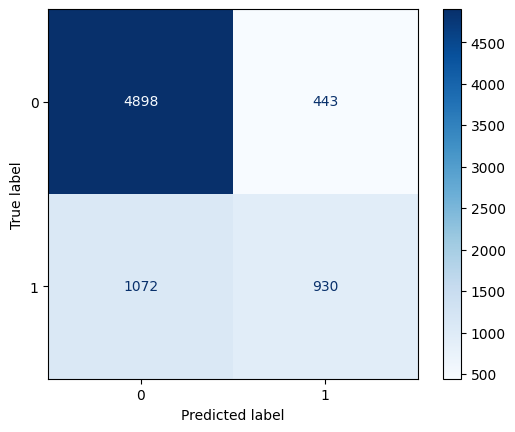

In [30]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(y_test, best_final_model_object.predict(X_test)))
ConfusionMatrixDisplay.from_estimator(best_final_model_object, X_test, y_test, cmap=plt.cm.Blues)
plt.show()